<p style=" position: absolute; top: 0; left:0; width: 100%; text-align: right;"><font size="2">Prof. Dr. Veronika Wanner-Seidl, Data Science II, Sommersemester 2025   </font> <br>


    
</p>

    
## KMeans Clustering 



In [3]:
# Required Libraries
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt 
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [4]:
# Function to plot final clusters
def plot_clusters_sklearn(data, labels, clusters):

    # Plot data points, choosing first two features for visualization
    plt.scatter(data[:, 0], data[:, 1], c=labels, cmap='viridis', label='Data points')

    # Plot cluster centers, also focusing on the same two features
    plt.scatter(clusters[:, 0], clusters[:, 1], s=200, color='red', marker='X', label='Centers')
    plt.title('Visualizing Clusters with Matplotlib using Iris Dataset')
    plt.xlabel('Sepal Length (cm)')
    plt.ylabel('Sepal Width (cm)')
    plt.legend()
    plt.grid(True)
    plt.show()

/tmp/ipykernel_14644/3621978534.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


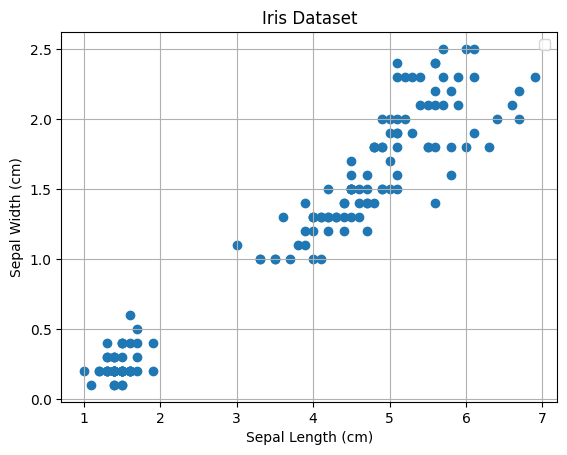

In [5]:
# Load the Iris dataset
iris = load_iris()
data = iris.data[:,2:4]

# Plot data points, choosing first two features for visualization
plt.scatter(data[:, 0], data[:, 1])

plt.title('Iris Dataset')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
k= 2
# k=3
#k = 5


# Perform K-means clustering and take cluster centers
kmeans_model = KMeans(n_clusters=2, n_init=10)
kmeans_model.fit(data)
labels = kmeans_model.labels_
clusters_sklearn = kmeans_model.cluster_centers_


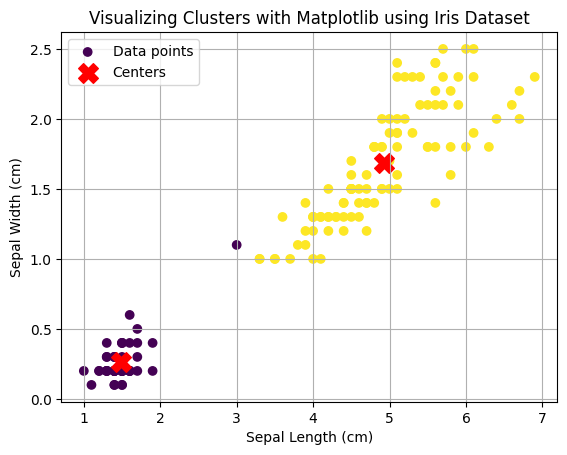

In [7]:
# Visualize the clusters
plot_clusters_sklearn(data, labels, clusters_sklearn)

In [8]:
silhouette_score(iris.target.reshape(-1, 1), labels)

np.float64(0.7314457239907438)

In [9]:
k = 3

# Perform K-means clustering and take cluster centers
kmeans_model = KMeans(n_clusters=k, n_init=10)
kmeans_model.fit(data)
labels = kmeans_model.labels_
clusters_sklearn = kmeans_model.cluster_centers_


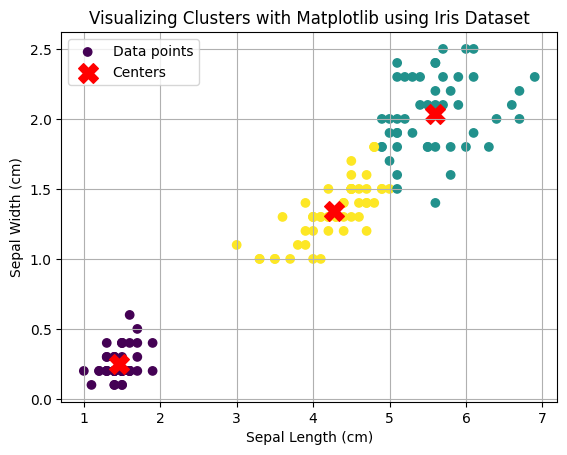

In [10]:
# Visualize the clusters
plot_clusters_sklearn(data, labels, clusters_sklearn)

In [11]:
silhouette_score(iris.target.reshape(-1, 1), labels)

np.float64(0.8819021189739684)

In [12]:
k = 5

# Perform K-means clustering and take cluster centers
kmeans_model = KMeans(n_clusters=k, n_init=10)
kmeans_model.fit(data)
labels = kmeans_model.labels_
clusters_sklearn = kmeans_model.cluster_centers_


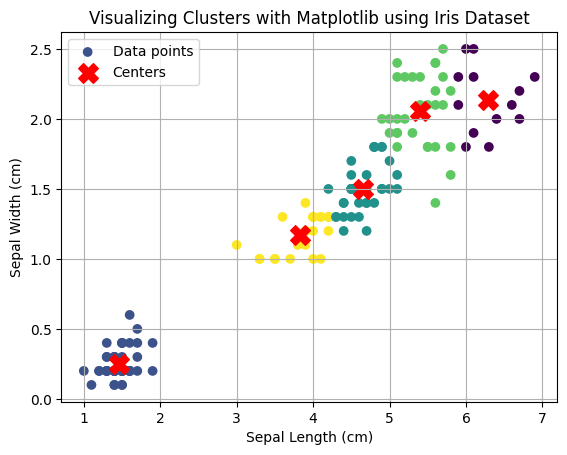

In [13]:
# Visualize the clusters
plot_clusters_sklearn(data, labels, clusters_sklearn)

In [14]:
silhouette_score(iris.target.reshape(-1, 1), labels)

np.float64(0.24666666666666667)

In [15]:
k = 5

# Perform K-means clustering and take cluster centers
good_init = np.array([[-3, 3], [-3, 2], [-3, 1], [-1, 2], [0, 2]])
kmeans_model = KMeans(n_clusters=k, n_init=10, init=good_init)
kmeans_model.fit(data)
labels = kmeans_model.labels_
clusters_sklearn = kmeans_model.cluster_centers_


/home/farouk/miniforge3/envs/data_science/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1396: RuntimeWarning: Explicit initial center position passed: performing only one init in KMeans instead of n_init=10.
  super()._check_params_vs_input(X, default_n_init=10)


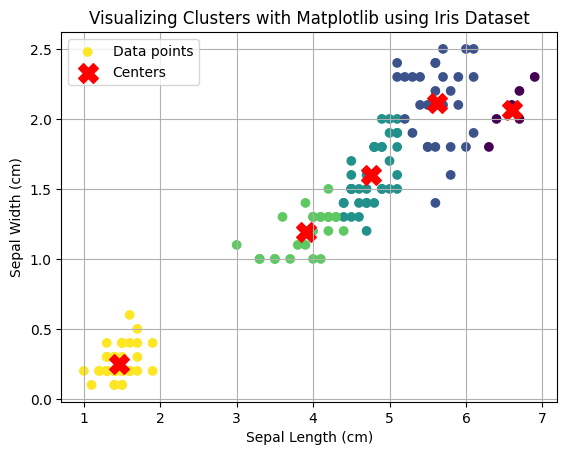

In [16]:
# Visualize the clusters
plot_clusters_sklearn(data, labels, clusters_sklearn)

In [17]:
silhouette_score(iris.target.reshape(-1, 1), labels)

np.float64(0.25333333333333335)

<p style=" position: absolute; top: 0; left:0; width: 100%; text-align: right;"><font size="2">Prof. Dr. Veronika Wanner-Seidl, Data Science II, Sommersemester 2025   </font> <br>


    
</p>

### KMeans - It doesn’t do well when ...


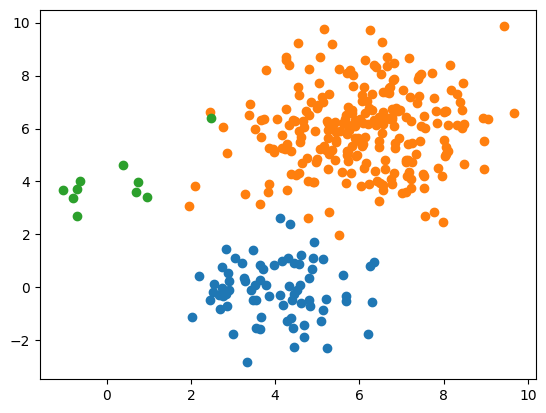

In [18]:
# Create data from three different multivariate distributions
X_1 = np.random.multivariate_normal(mean=[4, 0], cov=[[1, 0], [0, 1]], size=75)
X_2 = np.random.multivariate_normal(mean=[6, 6], cov=[[2, 0], [0, 2]], size=250)
X_3 = np.random.multivariate_normal(mean=[0, 4], cov=[[1, 0], [0, 0.5]], size=10)
df = np.concatenate([X_1, X_2, X_3])

# Plot the data
plt.scatter(X_1[:, 0], X_1[:, 1])
plt.scatter(X_2[:, 0], X_2[:, 1])
plt.scatter(X_3[:, 0], X_3[:, 1])


In [19]:
# Run kmeans
km = KMeans(n_clusters=3, n_init=100)
km.fit(df)
labels = km.predict(df)
centroids = km.cluster_centers_


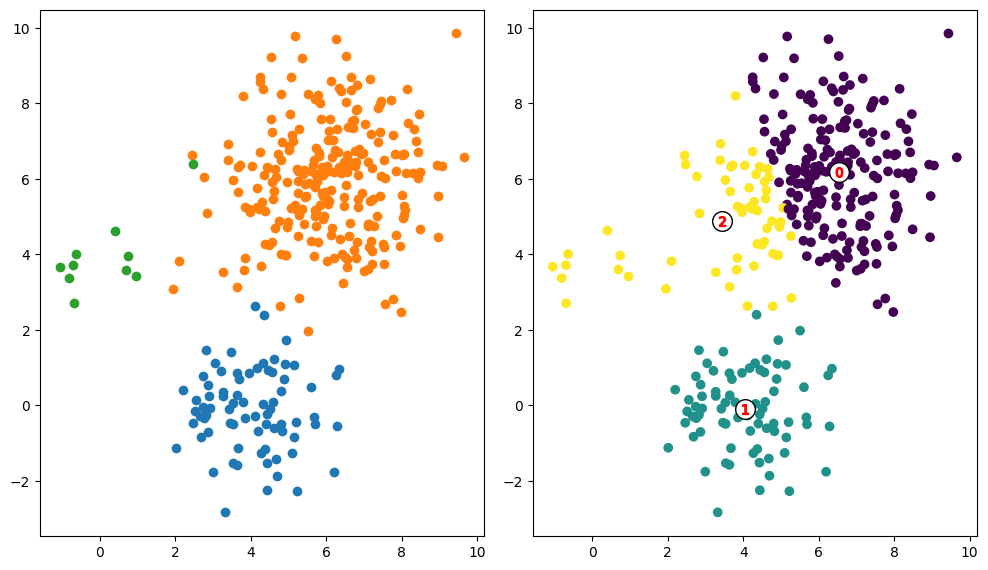

In [20]:
# Plot the data
fig, ax = plt.subplots(1, 2, figsize=(10, 10))
ax[0].scatter(X_1[:, 0], X_1[:, 1])
ax[0].scatter(X_2[:, 0], X_2[:, 1])
ax[0].scatter(X_3[:, 0], X_3[:, 1])
ax[0].set_aspect('equal')
ax[1].scatter(df[:, 0], df[:, 1], c=labels)
ax[1].scatter(centroids[:, 0], centroids[:, 1], marker='o',
                c="white", alpha=1, s=200, edgecolor='k')
for i, c in enumerate(centroids):
    ax[1].scatter(c[0], c[1], marker='$%d$' % i, s=50, alpha=1, edgecolor='r')
ax[1].set_aspect('equal')
plt.tight_layout()

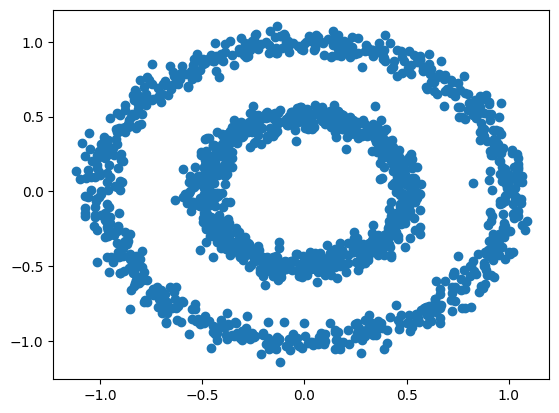

In [21]:
from sklearn.datasets import (make_blobs, make_circles, make_moons)
# Cricles
X = make_circles(factor=0.5, noise=0.05, n_samples=1500)

plt.scatter(X[0][:, 0], X[0][:, 1])

In [22]:
km = KMeans(n_clusters=2)
km.fit(X[0])
labels = km.predict(X[0])
centroids = km.cluster_centers_

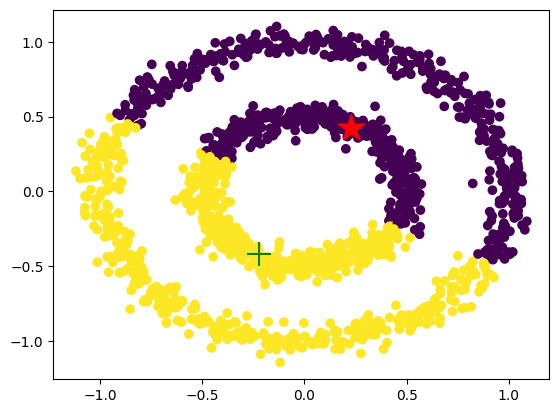

In [23]:
plt.scatter(X[0][:, 0], X[0][:, 1], c=labels)
plt.scatter(centroids[0, 0], centroids[0, 1], marker='*', s=400, c='r')
plt.scatter(centroids[1, 0], centroids[1, 1], marker='+', s=300, c='green')